In [1]:
import ollama

In [2]:
[print(i) for i in ollama.list().models]

model='qwen3.5:4b' modified_at=datetime.datetime(2026, 11, 22, 14, 33, 41, 356506, tzinfo=TzInfo(10800)) digest='d8b0f5e9760cd1682034f292d7ef72ec46f432149be0df7574bf2d6e92e38c04' size=3324173934 details=ModelDetails(parent_model='model.gguf', format='gguf', family='qwen35', families=['qwen35'], parameter_size='4.2B', quantization_level='Q4_K_M')
model='llama3.1:8b' modified_at=datetime.datetime(2025, 7, 6, 13, 36, 38, 320743, tzinfo=TzInfo(10800)) digest='46e0c10c039e019119339687c3c1757cc81b9da49709a3b3924863ba87ca666e' size=4920753328 details=ModelDetails(parent_model='', format='gguf', family='llama', families=['llama'], parameter_size='8.0B', quantization_level='Q4_K_M')


[None, None]

In [54]:
r_qwen = ollama.chat(model="qwen3:8b", messages=[{"role":"user",
                                        "content":"Истинно ли утверждение: 'Платон был учеником Аристотеля'?"}])

In [48]:
r = ollama.chat(model="llama3.2:3b", messages=[{"role":"user",
                                        "content":"Истинно ли утверждение: 'Платон был учеником Аристотеля'?"}])

In [108]:
r_qwen_mlx = ollama.chat(model="qwen3.5:9b-mlx", think=False, messages=[{"role":"user",
                                        "content":"Истинно ли утверждение: 'Платон был учеником Аристотеля'?"}])

In [3]:
r_qwen_mlx_4b = ollama.chat(model="qwen3.5:4b", think=False, messages=[{"role":"user",
                                        "content":"Истинно ли утверждение: 'Платон был учеником Аристотеля'?"}])

In [4]:
print(
      '\n \n QWEN 3.5 4B MLX: \n', r_qwen_mlx_4b.message.content
     )


 
 QWEN 3.5 4B MLX: 
 **Нет, это утверждение ложно.** Историческая хронология показывает, что эти两位 мыслителей не могли быть учителем и учеником друг друга.

Обратимся к датам их жизни:
*   **Платон** жил примерно с 428/427 до 348/347 гг. до н. э.
*   **Аристотель** родился около 384 г. до н. э. и умер в 322 г. до н. э.

Отсюда следует следующая последовательность событий:
1.  Платон учился под руководством Сократа (известного философа).
2.  Когда Аристотелю было около 17 лет (около 367 года до н.э.), он стал учеником Платона в Академии в Афинах на несколько лет. То есть сам **Аристотель был учеником Платона**.
3.  После смерти Платона Аристотель ушел из его круга и стал одним из крупнейших независимых философов той эпохи, а позже возглавил школу Ликеев в Стагиере, где воспитывал своих собственных учеников (например, Клеанта).

Таким образом, их отношение к вопросу было наоборот: **Аристотель был учеником Платона**, а не наоборот.


In [5]:
for response in [r_qwen_mlx_4b]:
    print("\n", response.model)
    print("Причина остановки:", response.done_reason)
    print("Входные токены:", response.prompt_eval_count)
    print("Выходные токены:", response.eval_count)
    print("Время генерации:", response.eval_duration / 1e9)
    print("Токенов/с:", response.eval_count * 1e9 / response.eval_duration)
    # print("Thinking:", len(response.message.thinking))
    # print("Content:", len(response.message.content))


 qwen3.5:4b
Причина остановки: stop
Входные токены: 32
Выходные токены: 306
Время генерации: 3.002659
Токенов/с: 101.90967405889246


In [75]:
from ollama import chat
from pathlib import Path
from pydantic import BaseModel, Field

use_model = "qwen3.5:9b"

text = Path("aristotle.txt").read_text(encoding="utf-8")

class Triple(BaseModel):
    subject: str
    predicate: str
    object: str


class Result(BaseModel):
    triples: list[Triple]


response_b_9b = chat(
    model = use_model,
    think = False,
    messages = [
        {
            "role": "system",
            "content": (
                "Извлекай из текста отношения в виде триплетов "
                "(субъект, предикат, объект). "
                "Предикат выражает отношение субъекта к объекту. "
                "Извлекай только явно выраженные отношения. "
                "Если отношение нельзя представить полноценным триплетом, пропусти его. "
                "Не добавляй информацию, отсутствующую в тексте. "
            )
        },
        {
            "role": "user",
            "content": text
        }
    ],
    format=Result.model_json_schema(),
    options={"temperature": 0},
)

In [65]:
result = Result.model_validate_json(response_b.message.content)

print("Токенов/с:", response_b.eval_count * 1e9 / response_b.eval_duration)
print("с:", response_b.eval_duration / 1e9)
print("\nТекст:\n")
print(text)
print("\nОтвет:\n")

for triple in result.triples:
    print(triple)

Токенов/с: 63.735433766644725
с: 6.69957

Текст:

Аристо́тель (др.-греч. Ἀριστοτέλης, 384 до н.э. — 322 до н.э.) — греческий философ и эрудит классического периода в Древней Греции, яркий пример «универсального человека».

Обученный Платоном, он был основателем перипатетической школы философии в Ликее и более широкой аристотелевской традиции. Его труды охватывают многие предметы, включая физику, биологию, зоологию, метафизику, логику, этику, эстетику, поэзию, театр, музыку, риторику, психологию, лингвистику, экономику, политику, метеорологию, геологию и государственное управление. Аристотель представил сложный синтез различных философий, существовавших до него. Прежде всего от его учений Запад унаследовал свой интеллектуальный лексикон, а также проблемы и методы исследования. В результате его философия оказала влияние почти на все формы знания на Западе и продолжает оставаться предметом современных философских дискуссий.

О его жизни известно немного. Аристотель родился в городе Стагир

- направленнность
- subject='Аристотель' predicate='попросил' object='Филиппа II Македонского обучать Александра Великого'
- слишком большие предикаты

### Два логических шага

In [67]:
MODEL = "qwen3.5:4b"

In [69]:
response_step_1 = chat(
    model=MODEL,
    messages=[
        {
            "role": "system",
            "content": (
                "Преобразуй текст в простые самостоятельные предложения. "
                "Каждое предложение должно содержать одно утверждение. "
                "Заменяй местоимения именами соответствующих сущностей. "
                "Сохраняй все факты, отрицания, неопределённость "
                "и временные связи. "
                "Не добавляй информацию от себя."
            )
        },
        {"role": "user", "content": text}
    ],
    think=False,
    options={"temperature": 0}
)

In [73]:
response_2steps = chat(
        model=MODEL,
        messages=[
            {
                "role": "system",
                "content": (
                    "Извлекай отношения из текста в виде триплетов "
                    "(субъект, предикат, объект). "
                    "Предикат должен выражать отношение субъекта к объекту. "
                    "Извлекай только явно выраженные отношения. "
                    "Не добавляй информацию от себя."
                )
            },
            {"role": "user", "content": response_step_1.message.content}
        ],
        format=Result.model_json_schema(),
        think=False,
        options={"temperature": 0}
    )

In [77]:
for response_name, response in {"Baseline 9B" : response_b,
                                #"Onthological" : response_o,
                                "Two-Steps 3B + 3B": response_2steps
                               }.items():
    print(f"\n=== Response: {response_name} ===\n")
    print("Токенов/с:", response.eval_count * 1e9 / response.eval_duration)
    print("с:", response.eval_duration / 1e9)
    print("\nТекст:\n")
    print(text)
    print("\nОтвет:\n")
    result = Result.model_validate_json(response.message.content)
    for triple in result.triples:
        print(triple)


=== Response: Baseline 9B ===

Токенов/с: 63.735433766644725
с: 6.69957

Текст:

Аристо́тель (др.-греч. Ἀριστοτέλης, 384 до н.э. — 322 до н.э.) — греческий философ и эрудит классического периода в Древней Греции, яркий пример «универсального человека».

Обученный Платоном, он был основателем перипатетической школы философии в Ликее и более широкой аристотелевской традиции. Его труды охватывают многие предметы, включая физику, биологию, зоологию, метафизику, логику, этику, эстетику, поэзию, театр, музыку, риторику, психологию, лингвистику, экономику, политику, метеорологию, геологию и государственное управление. Аристотель представил сложный синтез различных философий, существовавших до него. Прежде всего от его учений Запад унаследовал свой интеллектуальный лексикон, а также проблемы и методы исследования. В результате его философия оказала влияние почти на все формы знания на Западе и продолжает оставаться предметом современных философских дискуссий.

О его жизни известно немного. Ар

In [78]:
for response_name, response in {
    "Baseline 9B": response_b,
    "Two-Steps 3B + 3B": response_2steps
}.items():
    print(f"\n=== Response: {response_name} ===\n")

    input_tokens = response.prompt_eval_count
    output_tokens = response.eval_count

    print("Входных токенов:", input_tokens)
    print("Выходных токенов:", output_tokens)
    print("Всего токенов:", input_tokens + output_tokens)
    print("Токенов/с:", output_tokens * 1e9 / response.eval_duration)
    print("Генерация, с:", response.eval_duration / 1e9)
    print("Полное время, с:", response.total_duration / 1e9)

    print("\nТекст:\n", text)
    print("\nОтвет:\n")

    result = Result.model_validate_json(response.message.content)
    for triple in result.triples:
        print(triple)


=== Response: Baseline 9B ===

Входных токенов: 563
Выходных токенов: 427
Всего токенов: 990
Токенов/с: 63.735433766644725
Генерация, с: 6.69957
Полное время, с: 9.3562186

Текст:
 Аристо́тель (др.-греч. Ἀριστοτέλης, 384 до н.э. — 322 до н.э.) — греческий философ и эрудит классического периода в Древней Греции, яркий пример «универсального человека».

Обученный Платоном, он был основателем перипатетической школы философии в Ликее и более широкой аристотелевской традиции. Его труды охватывают многие предметы, включая физику, биологию, зоологию, метафизику, логику, этику, эстетику, поэзию, театр, музыку, риторику, психологию, лингвистику, экономику, политику, метеорологию, геологию и государственное управление. Аристотель представил сложный синтез различных философий, существовавших до него. Прежде всего от его учений Запад унаследовал свой интеллектуальный лексикон, а также проблемы и методы исследования. В результате его философия оказала влияние почти на все формы знания на Западе и 

#### ChatGPT eval

In [79]:
tokens_2steps = sum(
    r.prompt_eval_count + r.eval_count
    for r in (response_step_1, response_2steps)
)

print("Токенов на триплет:", tokens_2steps / 36)
print("Токенов на корректный триплет:", tokens_2steps / 33)

Токенов на триплет: 94.83333333333333
Токенов на корректный триплет: 103.45454545454545


| Метрика | Baseline 9B | Two-Steps 3B + 3B |
|---|---:|---:|
| Извлечено триплетов | 10 | 36 |
| Подтверждено текстом | 10 | 33 |
| Precision | 100% | 91,7% |
| Recall* | 21,7% | 71,7% |
| F1* | 35,7% | 80,5% |
| Токенов на триплет | 99 | 94,8 |
| Токенов на корректный триплет | 99 | 103,5 |

- Возможно оценка смещена из-за отношение с **труды охватывают** 

#### Plato retest

In [124]:
from ollama import chat
from pathlib import Path
from pydantic import BaseModel, Field

use_model = "qwen3.5:9b"

text = Path("plato.txt").read_text(encoding="utf-8")

class Triple(BaseModel):
    subject: str
    predicate: str
    object: str


class Result(BaseModel):
    triples: list[Triple]

def baseline(model):
    r = chat(
        model = model,
        think = False,
        messages = [
            {
                "role": "system",
                "content": (
                    "Извлекай из текста отношения в виде триплетов "
                    "(субъект, предикат, объект). "
                    "Предикат выражает отношение субъекта к объекту. "
                    "Извлекай только явно выраженные отношения. "
                    "Если отношение нельзя представить полноценным триплетом, пропусти его. "
                    "Не добавляй информацию, отсутствующую в тексте. "
                )
            },
            {
                "role": "user",
                "content": text
            }
        ],
        format=Result.model_json_schema(),
        options={"temperature": 0},
    )
    return r

response_b_4b_plato = baseline("qwen3.5:4b")

response_b_9b_plato = baseline("qwen3.5:9b")

In [102]:
def two_step(model1, model2=None):
    if model2 == None:
        model2 = model1
    response_step_1_plato = chat(
        model=model1,
        messages=[
            {
                "role": "system",
                "content": (
                    "Преобразуй текст в простые самостоятельные предложения. "
                    "Каждое предложение должно содержать одно утверждение. "
                    "Заменяй местоимения именами соответствующих сущностей. "
                    "Сохраняй все факты, отрицания, неопределённость "
                    "и временные связи. "
                    "Не добавляй информацию от себя."
                )
            },
            {"role": "user", "content": text}
        ],
        think=False,
        options={"temperature": 0}
    )
    
    response_2steps_plato = chat(
            model=model2,
            messages=[
                {
                    "role": "system",
                    "content": (
                        "Извлекай отношения из текста в виде триплетов "
                        "(субъект, предикат, объект). "
                        "Предикат должен выражать отношение субъекта к объекту. "
                        "Извлекай только явно выраженные отношения. "
                        "Не добавляй информацию от себя."
                    )
                },
                {"role": "user", "content": response_step_1_plato.message.content}
            ],
            format=Result.model_json_schema(),
            think=False,
            options={"temperature": 0}
    )

    return response_step_1_plato, response_2steps_plato

response_step_1_plato, response_2steps_plato = two_step("qwen3.5:4b")

response_step_1_plato_9b, response_2steps_plato_9b = two_step("qwen3.5:9b")

response_step_1_plato_4b_9b, response_2steps_plato_4b_9b = two_step("qwen3.5:4b", "qwen3.5:9b")

response_step_1_plato_9b_4b, response_2steps_plato_9b_4b = two_step("qwen3.5:9b", "qwen3.5:4b")

In [125]:
responses_step_1 = {
    "4B → 4B": response_step_1_plato,
    "9B → 9B": response_step_1_plato_9b,
    "4B → 9B": response_step_1_plato_4b_9b,
    "9B → 4B": response_step_1_plato_9b_4b,
}

for name, r in responses_step_1.items():
    print(f"\n=== {name}: первый этап ===")
    print("Входных токенов:", r.prompt_eval_count)
    print("Выходных токенов:", r.eval_count)
    print("Полное время, с:", r.total_duration / 1e9)
    print("\nДекомпозированный текст:\n", r.message.content)


=== 4B → 4B: первый этап ===
Входных токенов: 463
Выходных токенов: 418
Полное время, с: 4.4479005

Декомпозированный текст:
 Аристотель был учеником Платона.
Сократ был учителем Платона.
Платон считается одним из самых важных людей в истории человечества.
Платон является ключевой фигурой в истории древнегреческой философии.
Платон является ключевой фигурой в истории западной философии.
Аристотель является самым известным учеником Платона.
Некоторые люди называют Платона основателем западной религии и духовности.
Философы неоплатонизма, такие как Плотин и Порфирий, сильно повлияли на христианство.
Плотин был философом неоплатонизма.
Порфирий был философом неоплатонизма.
Августин был отцом церкви.
Августин был受影响 (под влиянием) философов неоплатонизма.
Альфред Норт Уайтхед заметил, что европейская философская традиция представляет собой серию примечаний к Платону.
Платон был новатором письменного диалога в философии.
Платон был новатором диалектических форм в философии.
Платон считаетс

In [126]:
for response_name, response in {
    "Baseline 4B" : response_b_4b_plato,
    "Baseline 9B" : response_b_9b_plato,
    "Two-Steps 4B + 4B": response_2steps_plato,
    "Two-Steps 4B + 9B": response_2steps_plato_4b_9b,
    "Two-Steps 9B + 4B": response_2steps_plato_9b_4b,
    "Two-Steps 9B + 9B": response_2steps_plato_9b
}.items():
    print(f"\n=== Response: {response_name} ===\n")

    input_tokens = response.prompt_eval_count
    output_tokens = response.eval_count

    print("Входных токенов:", input_tokens)
    print("Выходных токенов:", output_tokens)
    print("Всего токенов:", input_tokens + output_tokens)
    print("Токенов/с:", output_tokens * 1e9 / response.eval_duration)
    print("Генерация, с:", response.eval_duration / 1e9)
    print("Полное время, с:", response.total_duration / 1e9)

    print("\nТекст:\n", text)
    print("\nОтвет:\n")

    result = Result.model_validate_json(response.message.content)
    for triple in result.triples:
        print(triple)


=== Response: Baseline 4B ===

Входных токенов: 468
Выходных токенов: 800
Всего токенов: 1268
Токенов/с: 99.59819597787626
Генерация, с: 8.032274
Полное время, с: 10.5154599

Текст:
                 Плато́н (др.-греч. Πλάτων; 428/427 или 424/423 — 348/347 до н. э.), настоящее имя Аристо́кл — афинский философ классического периода Древней Греции, основатель платонической школы мысли и Академии, первого высшего учебного заведения в западном мире.
                Он считается одним из самых важных и влиятельных людей в истории человечества[1], и ключевой фигурой в истории древнегреческой и западной философии — вместе со своим учителем Сократом и самым известным из своих учеников Аристотелем[~ 1]. Часто Платона также называют одним из основателей западной религии и духовности[2]. Так называемый неоплатонизм философов, таких как Плотин и Порфирий, сильно повлиял на христианство через таких отцов церкви как Августин. Альфред Норт Уайтхед однажды заметил: «Наиболее правдоподобная общая харак

### Final GPT Eval

In [129]:
import pandas as pd

GOLD_SIZE = 30

# Baseline: количество, токены, полное время
baselines = {
    "Baseline 4B": (23, 1268, 10.6573436),
    "Baseline 9B": (7, 758, 4.5664844),
}

# Двухэтапные конфигурации
pipelines = {
    "4B → 4B": (response_step_1_plato, response_2steps_plato),
    "4B → 9B": (response_step_1_plato_4b_9b, response_2steps_plato_4b_9b),
    "9B → 4B": (response_step_1_plato_9b_4b, response_2steps_plato_9b_4b),
    "9B → 9B": (response_step_1_plato_9b, response_2steps_plato_9b),
}

# Экспертная оценка количества верных триплетов
correct = {
    "Baseline 4B": 17,
    "Baseline 9B": 5,
    "4B → 4B": 6,
    "4B → 9B": 14,
    "9B → 4B": 14,
    "9B → 9B": 20,
}

rows = []

for name in [*baselines, *pipelines]:
    if name in baselines:
        n, total_tokens, total_seconds = baselines[name]
    else:
        step1, step2 = pipelines[name]

        n = len(Result.model_validate_json(
            step2.message.content
        ).triples)

        total_tokens = sum(
            (r.prompt_eval_count or 0) + (r.eval_count or 0)
            for r in (step1, step2)
        )
        total_seconds = sum(
            (r.total_duration or 0) / 1e9
            for r in (step1, step2)
        )

    tp = correct[name]
    precision = tp / n
    recall = tp / GOLD_SIZE
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0
    )

    rows.append({
        "Конфигурация": name,
        "Триплеты": n,
        "Из них, верных": tp,
        "Ошибок": n - tp,
        "Precision, %": precision * 100,
        "Recall, %": recall * 100,
        "F1, %": f1 * 100,
        "Токены": total_tokens,
        "Время, с": total_seconds,
        "Токенов/триплет": total_tokens / n,
        "Токенов/верный": total_tokens / tp,
        "Секунд/верный": total_seconds / tp,
    })

df = pd.DataFrame(rows).set_index("Конфигурация")

display(df.round(1))


,Триплеты,"Из них, верных",Ошибок,"Precision, %","Recall, %","F1, %",Токены,"Время, с",Токенов/триплет,Токенов/верный,Секунд/верный
Конфигурация,,,,,,,,,,,
Baseline 4B,23,17,6,73.9,56.7,64.2,1268,10.7,55.1,74.6,0.6
Baseline 9B,7,5,2,71.4,16.7,27.0,758,4.6,108.3,151.6,0.9
4B → 4B,23,6,17,26.1,20.0,22.6,2192,12.9,95.3,365.3,2.1
4B → 9B,23,14,9,60.9,46.7,52.8,2350,19.8,102.2,167.9,1.4
9B → 4B,23,14,9,60.9,46.7,52.8,2107,14.4,91.6,150.5,1.0
9B → 9B,22,20,2,90.9,66.7,76.9,2306,21.7,104.8,115.3,1.1


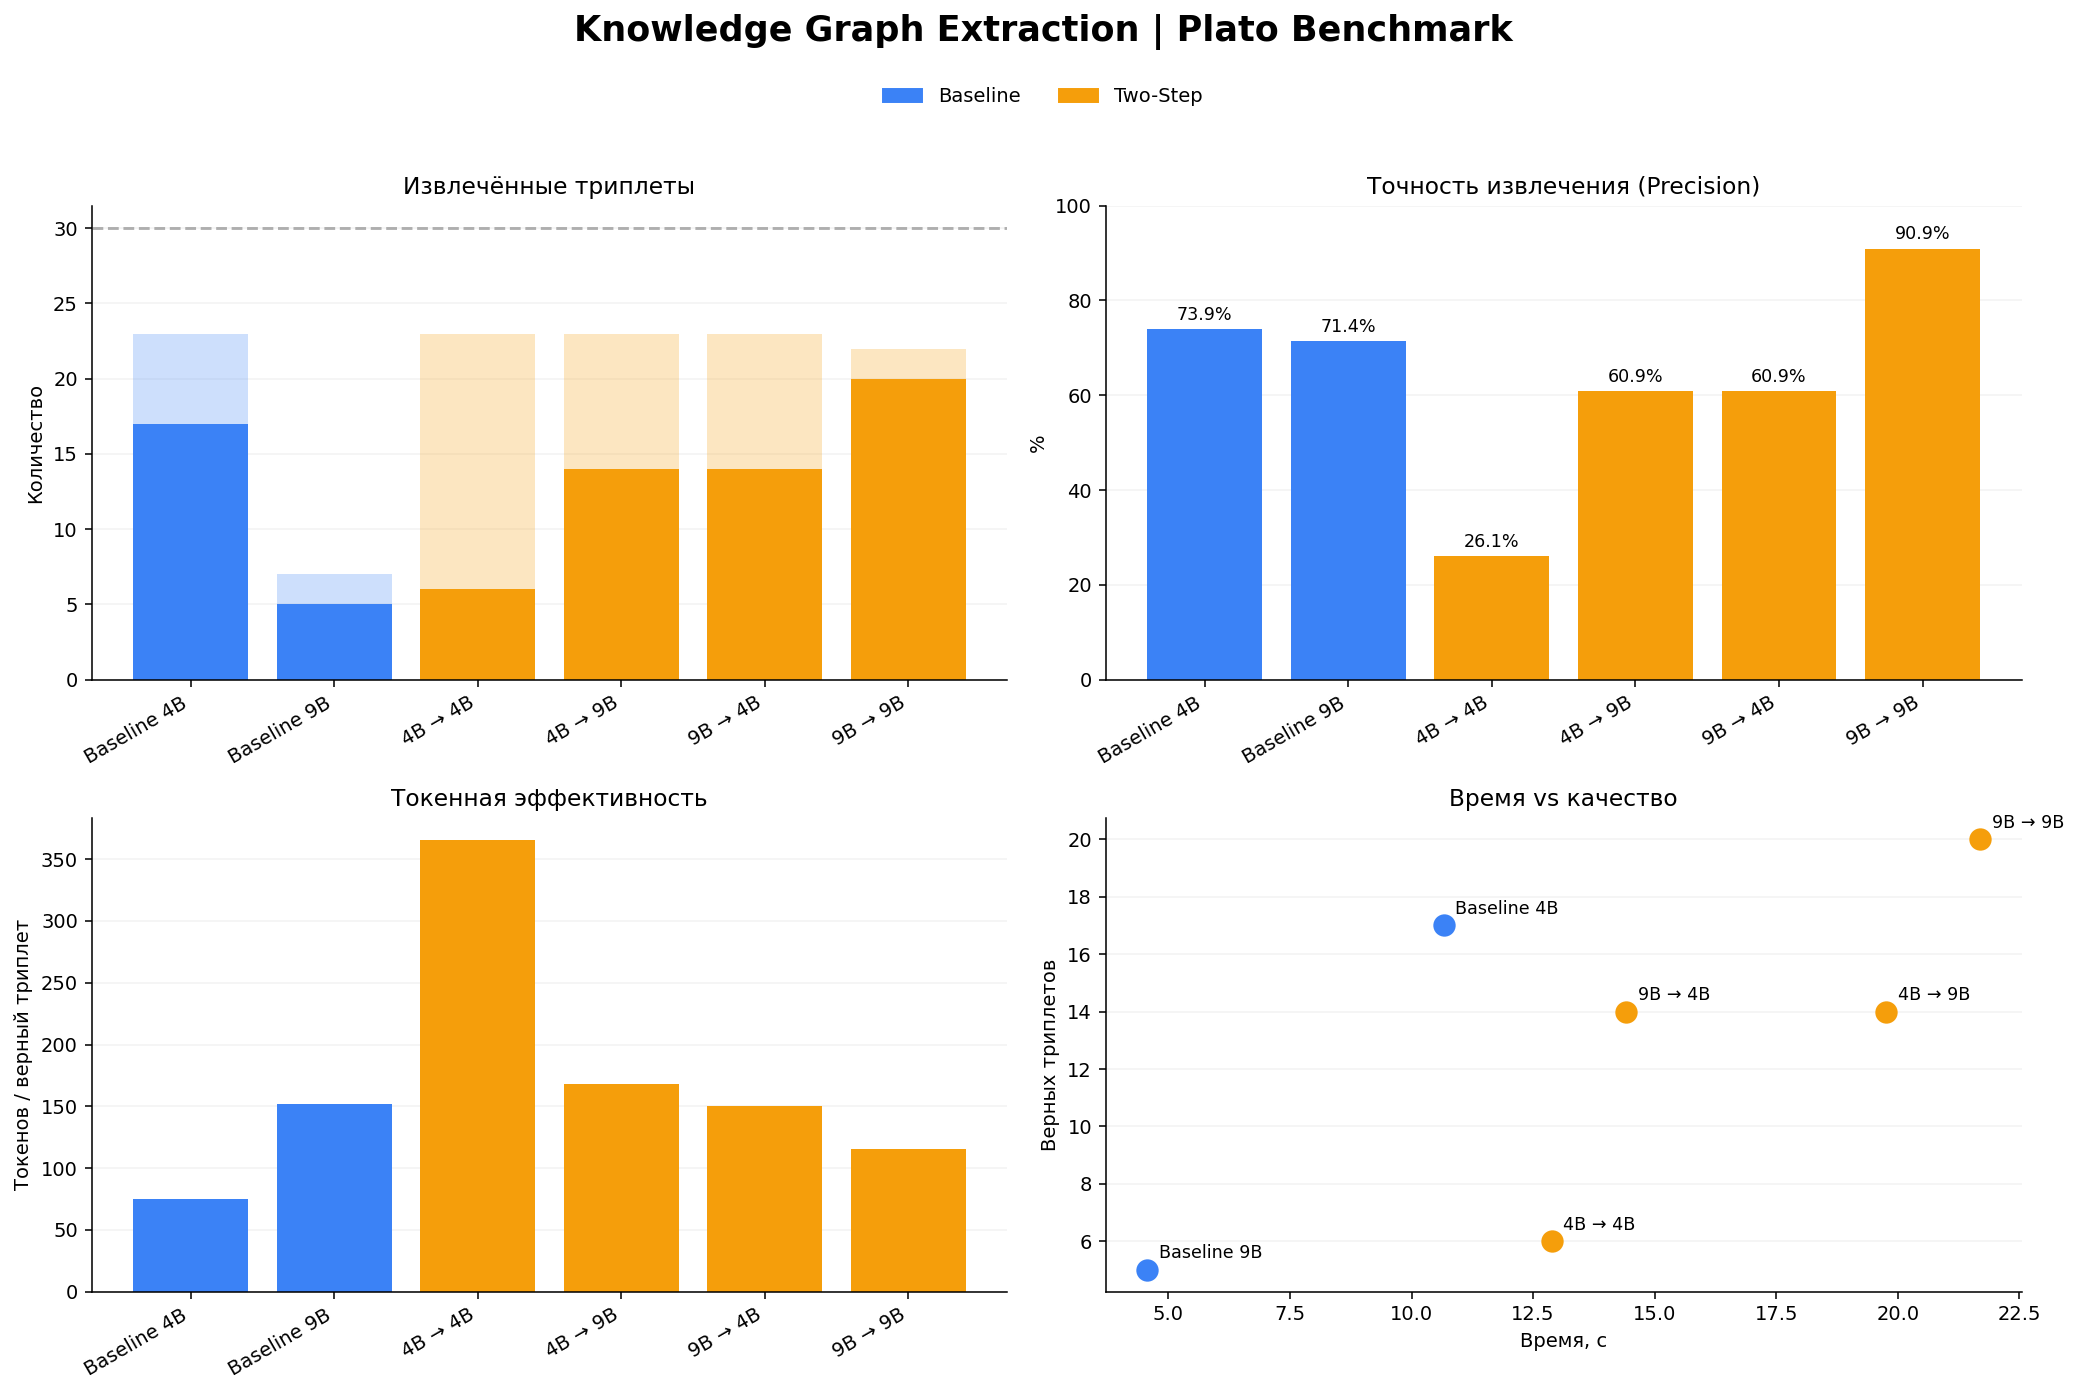

In [130]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch

# Цвета конфигураций
colors = {
    "baseline": "#3B82F6",
    "two_step": "#F59E0B",
}
names = df.index.tolist()
bar_colors = [
    colors["two_step"] if "→" in name else colors["baseline"]
    for name in names
]
x = np.arange(len(names))

plt.rcParams.update({
    "figure.dpi": 140,
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
ax1, ax2, ax3, ax4 = axes.flatten()

# 1. Извлечённые и верные триплеты
ax1.bar(x, df["Триплеты"], color=bar_colors, alpha=0.25)
ax1.bar(x, df["Из них, верных"], color=bar_colors)
ax1.axhline(30, color="gray", linestyle="--", alpha=0.6)
ax1.set_title("Извлечённые триплеты")
ax1.set_ylabel("Количество")

# 2. Precision
bars = ax2.bar(x, df["Precision, %"], color=bar_colors)
ax2.set_title("Точность извлечения (Precision)")
ax2.set_ylabel("%")
ax2.set_ylim(0, 100)

for bar in bars:
    ax2.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 2,
        f"{bar.get_height():.1f}%",
        ha="center", fontsize=9
    )

# 3. Токены на верный триплет
ax3.bar(x, df["Токенов/верный"], color=bar_colors)
ax3.set_title("Токенная эффективность")
ax3.set_ylabel("Токенов / верный триплет")

# 4. Время vs число верных триплетов
for name, row in df.iterrows():
    color = (
        colors["two_step"] if "→" in name
        else colors["baseline"]
    )
    ax4.scatter(
        row["Время, с"],
        row["Из них, верных"],
        color=color, s=110
    )
    ax4.annotate(
        name,
        (row["Время, с"], row["Из них, верных"]),
        xytext=(6, 6),
        textcoords="offset points",
        fontsize=9,
    )

ax4.set_title("Время vs качество")
ax4.set_xlabel("Время, с")
ax4.set_ylabel("Верных триплетов")

# Общие настройки
for ax in [ax1, ax2, ax3]:
    ax.set_xticks(x)
    ax.set_xticklabels(names, rotation=30, ha="right")

for ax in axes.flatten():
    ax.grid(axis="y", alpha=0.15)
    ax.set_axisbelow(True)

fig.legend(
    handles=[
        Patch(color=colors["baseline"], label="Baseline"),
        Patch(color=colors["two_step"], label="Two-Step"),
    ],
    loc="upper center",
    bbox_to_anchor=(0.5, 0.95),
    ncol=2,
    frameon=False
)

fig.suptitle(
    "Knowledge Graph Extraction | Plato Benchmark",
    fontsize=18, fontweight="bold", y=0.99
)

plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.savefig("plato_benchmark.png", dpi=250, bbox_inches="tight")
plt.show()


### Another final eval

In [131]:
from ollama import chat
from pydantic import BaseModel
import pandas as pd

MODEL_4B = "qwen3.5:4b"
MODEL_9B = "qwen3.5:9b"

class Triple(BaseModel):
    subject: str
    predicate: str
    object: str

class Result(BaseModel):
    triples: list[Triple]


SIMPLIFY_PROMPT = (
    "Преобразуй текст в простые самостоятельные предложения. "
    "Каждое предложение должно содержать одно утверждение. "
    "Заменяй местоимения именами соответствующих сущностей. "
    "Сохраняй все факты, отрицания, неопределённость "
    "и временные связи. "
    "Не добавляй информацию от себя."
)

EXTRACT_PROMPT = (
    "Ты извлекаешь отношения из текста в виде триплетов "
    "(субъект, предикат, объект). "
    "Предикат должен выражать отношение субъекта к объекту, "
    "а не объекта к субъекту. "
    "Каждое отношение должно иметь все три составные части. "
    "Извлекай только явно выраженные отношения. "
    "Не добавляй информацию от себя."
)


def ask(model, system_prompt, text, structured=False):
    return chat(
        model=model,
        messages=[
            {"role": "system", "content": system_prompt},
            {"role": "user", "content": text},
        ],
        format=Result.model_json_schema() if structured else None,
        think=False,
        options={"temperature": 0},
    )


def extract(text, model):
    return ask(model, EXTRACT_PROMPT, text, structured=True)


def two_step(text, model_1, model_2):
    step_1 = ask(model_1, SIMPLIFY_PROMPT, text)
    step_2 = extract(step_1.message.content, model_2)
    return step_1, step_2


def get_metrics(responses):
    total_tokens = sum(
        (r.prompt_eval_count or 0) + (r.eval_count or 0)
        for r in responses
    )
    total_seconds = sum(
        (r.total_duration or 0) / 1e9
        for r in responses
    )
    return total_tokens, total_seconds


def benchmark(text):
    configs = {
        "Baseline 4B": (MODEL_4B,),
        "Baseline 9B": (MODEL_9B,),
        "4B → 4B": (MODEL_4B, MODEL_4B),
        "4B → 9B": (MODEL_4B, MODEL_9B),
        "9B → 4B": (MODEL_9B, MODEL_4B),
        "9B → 9B": (MODEL_9B, MODEL_9B),
    }

    results = {}
    rows = []

    for name, models in configs.items():
        print(f"Запуск: {name}")

        if len(models) == 1:
            responses = (extract(text, models[0]),)
        else:
            responses = two_step(text, *models)

        triples = Result.model_validate_json(
            responses[-1].message.content
        ).triples

        n = len(triples)
        tokens, seconds = get_metrics(responses)

        results[name] = {
            "responses": responses,
            "triples": triples,
            "decomposed_text": (
                responses[0].message.content
                if len(responses) == 2 else None
            ),
        }

        rows.append({
            "Конфигурация": name,
            "Триплеты": n,
            "Токены": tokens,
            "Время, с": seconds,
            "Токенов/триплет": tokens / n if n else None,
            "Секунд/триплет": seconds / n if n else None,
        })

    df = pd.DataFrame(rows).set_index("Конфигурация")
    return df, results


In [132]:
def evaluate(df, correct, gold_size=30):
    df = df.copy()

    df["Из них, верных"] = pd.Series(correct)
    df["Ошибок"] = df["Триплеты"] - df["Из них, верных"]

    df["Precision, %"] = (
        df["Из них, верных"] / df["Триплеты"] * 100
    )

    df["Recall*, %"] = (
        df["Из них, верных"] / gold_size * 100
    )

    p = df["Precision, %"]
    r = df["Recall*, %"]

    df["F1*, %"] = (
        2 * p * r / (p + r).replace(0, float("nan"))
    ).fillna(0)

    df["Токенов/верный"] = (
        df["Токены"] / df["Из них, верных"].replace(0, float("nan"))
    )

    df["Секунд/верный"] = (
        df["Время, с"] / df["Из них, верных"].replace(0, float("nan"))
    )

    return df

In [133]:

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch

def plot_benchmark(df, title="Knowledge Graph Extraction"):
    names = df.index.tolist()
    colors = [
        "#F59E0B" if "→" in name else "#3B82F6"
        for name in names
    ]
    x = np.arange(len(names))
    graded = "Из них, верных" in df.columns

    plt.rcParams.update({
        "figure.dpi": 140,
        "font.size": 10,
        "axes.spines.top": False,
        "axes.spines.right": False,
    })

    fig, axes = plt.subplots(2, 2, figsize=(15, 10))
    ax1, ax2, ax3, ax4 = axes.flatten()

    # 1. Извлечённые и правильные
    ax1.bar(x, df["Триплеты"], color=colors, alpha=0.25)

    if graded:
        ax1.bar(x, df["Из них, верных"], color=colors)

    ax1.set_title("Извлечённые триплеты")
    ax1.set_ylabel("Количество")

    # 2. Precision либо количество триплетов
    if graded:
        values = df["Precision, %"]
        ax2.set_title("Precision")
        ax2.set_ylabel("%")
        ax2.set_ylim(0, 110)
    else:
        values = df["Триплеты"]
        ax2.set_title("Объём извлечения")
        ax2.set_ylabel("Триплеты")

    bars = ax2.bar(x, values, color=colors)

    for bar in bars:
        h = bar.get_height()
        ax2.annotate(
            f"{h:.1f}%" if graded else f"{h:.0f}",
            (bar.get_x() + bar.get_width()/2, h),
            xytext=(0, 4),
            textcoords="offset points",
            ha="center",
        )

    # 3. Токенная эффективность
    metric = "Токенов/верный" if graded else "Токенов/триплет"

    ax3.bar(x, df[metric], color=colors)
    ax3.set_title("Токенная эффективность")
    ax3.set_ylabel(metric)

    # 4. Время vs результат
    y_metric = "Из них, верных" if graded else "Триплеты"

    for name, row in df.iterrows():
        color = "#F59E0B" if "→" in name else "#3B82F6"

        ax4.scatter(
            row["Время, с"],
            row[y_metric],
            color=color,
            s=110,
        )

        ax4.annotate(
            name,
            (row["Время, с"], row[y_metric]),
            xytext=(6, 6),
            textcoords="offset points",
            fontsize=9,
        )

    ax4.set_title("Время vs качество" if graded else "Время vs объём")
    ax4.set_xlabel("Время, с")
    ax4.set_ylabel(y_metric)

    for ax in (ax1, ax2, ax3):
        ax.set_xticks(x)
        ax.set_xticklabels(names, rotation=30, ha="right")

    for ax in axes.flatten():
        ax.grid(axis="y", alpha=0.15)
        ax.set_axisbelow(True)

    fig.legend(
        handles=[
            Patch(color="#3B82F6", label="Baseline"),
            Patch(color="#F59E0B", label="Two-Step"),
        ],
        loc="upper center",
        bbox_to_anchor=(0.5, 0.95),
        ncol=2,
        frameon=False,
    )

    fig.suptitle(title, fontsize=18, fontweight="bold", y=0.99)
    plt.tight_layout(rect=[0, 0, 1, 0.93])

    return fig


Запуск: Baseline 4B
Запуск: Baseline 9B
Запуск: 4B → 4B
Запуск: 4B → 9B
Запуск: 9B → 4B
Запуск: 9B → 9B

=== Baseline 4B ===
subject='Александр Македонский' predicate='был царём' object='Македонии'
subject='Александр Македонский' predicate='принадлежал к династии' object='Аргеадов'
subject='Александр Македонский' predicate='был полководцем' object='выдающимся'
subject='Александр Македонский' predicate='создал державу' object='мировую'
subject='Александр Македонский' predicate='разгромил сатрапов' object='при Гранике'
subject='Александр Македонский' predicate='разгромил царя' object='Дария III при Иссе'
subject='Александр Македонский' predicate='подчинил Сирию' object='Иудею и Египет'
subject='Александр Македонский' predicate='одержал победу' object='при Гавгамелах в Месопотамии'
subject='Александр Македонский' predicate='принял титул' object='царь Азии'
subject='Александр Македонский' predicate='завоевал Среднюю Азию' object='за три года (329—326 годы до н. э.)'
subject='Александр Маке

,Триплеты,Токены,"Время, с",Токенов/триплет,Секунд/триплет
Конфигурация,,,,,
Baseline 4B,46,3038,19.6,66.0,0.4
Baseline 9B,59,3105,30.2,52.6,0.5
4B → 4B,59,5859,32.7,99.3,0.6
4B → 9B,73,6104,47.1,83.6,0.6
9B → 4B,62,5850,39.7,94.4,0.6
9B → 9B,70,5966,52.5,85.2,0.7


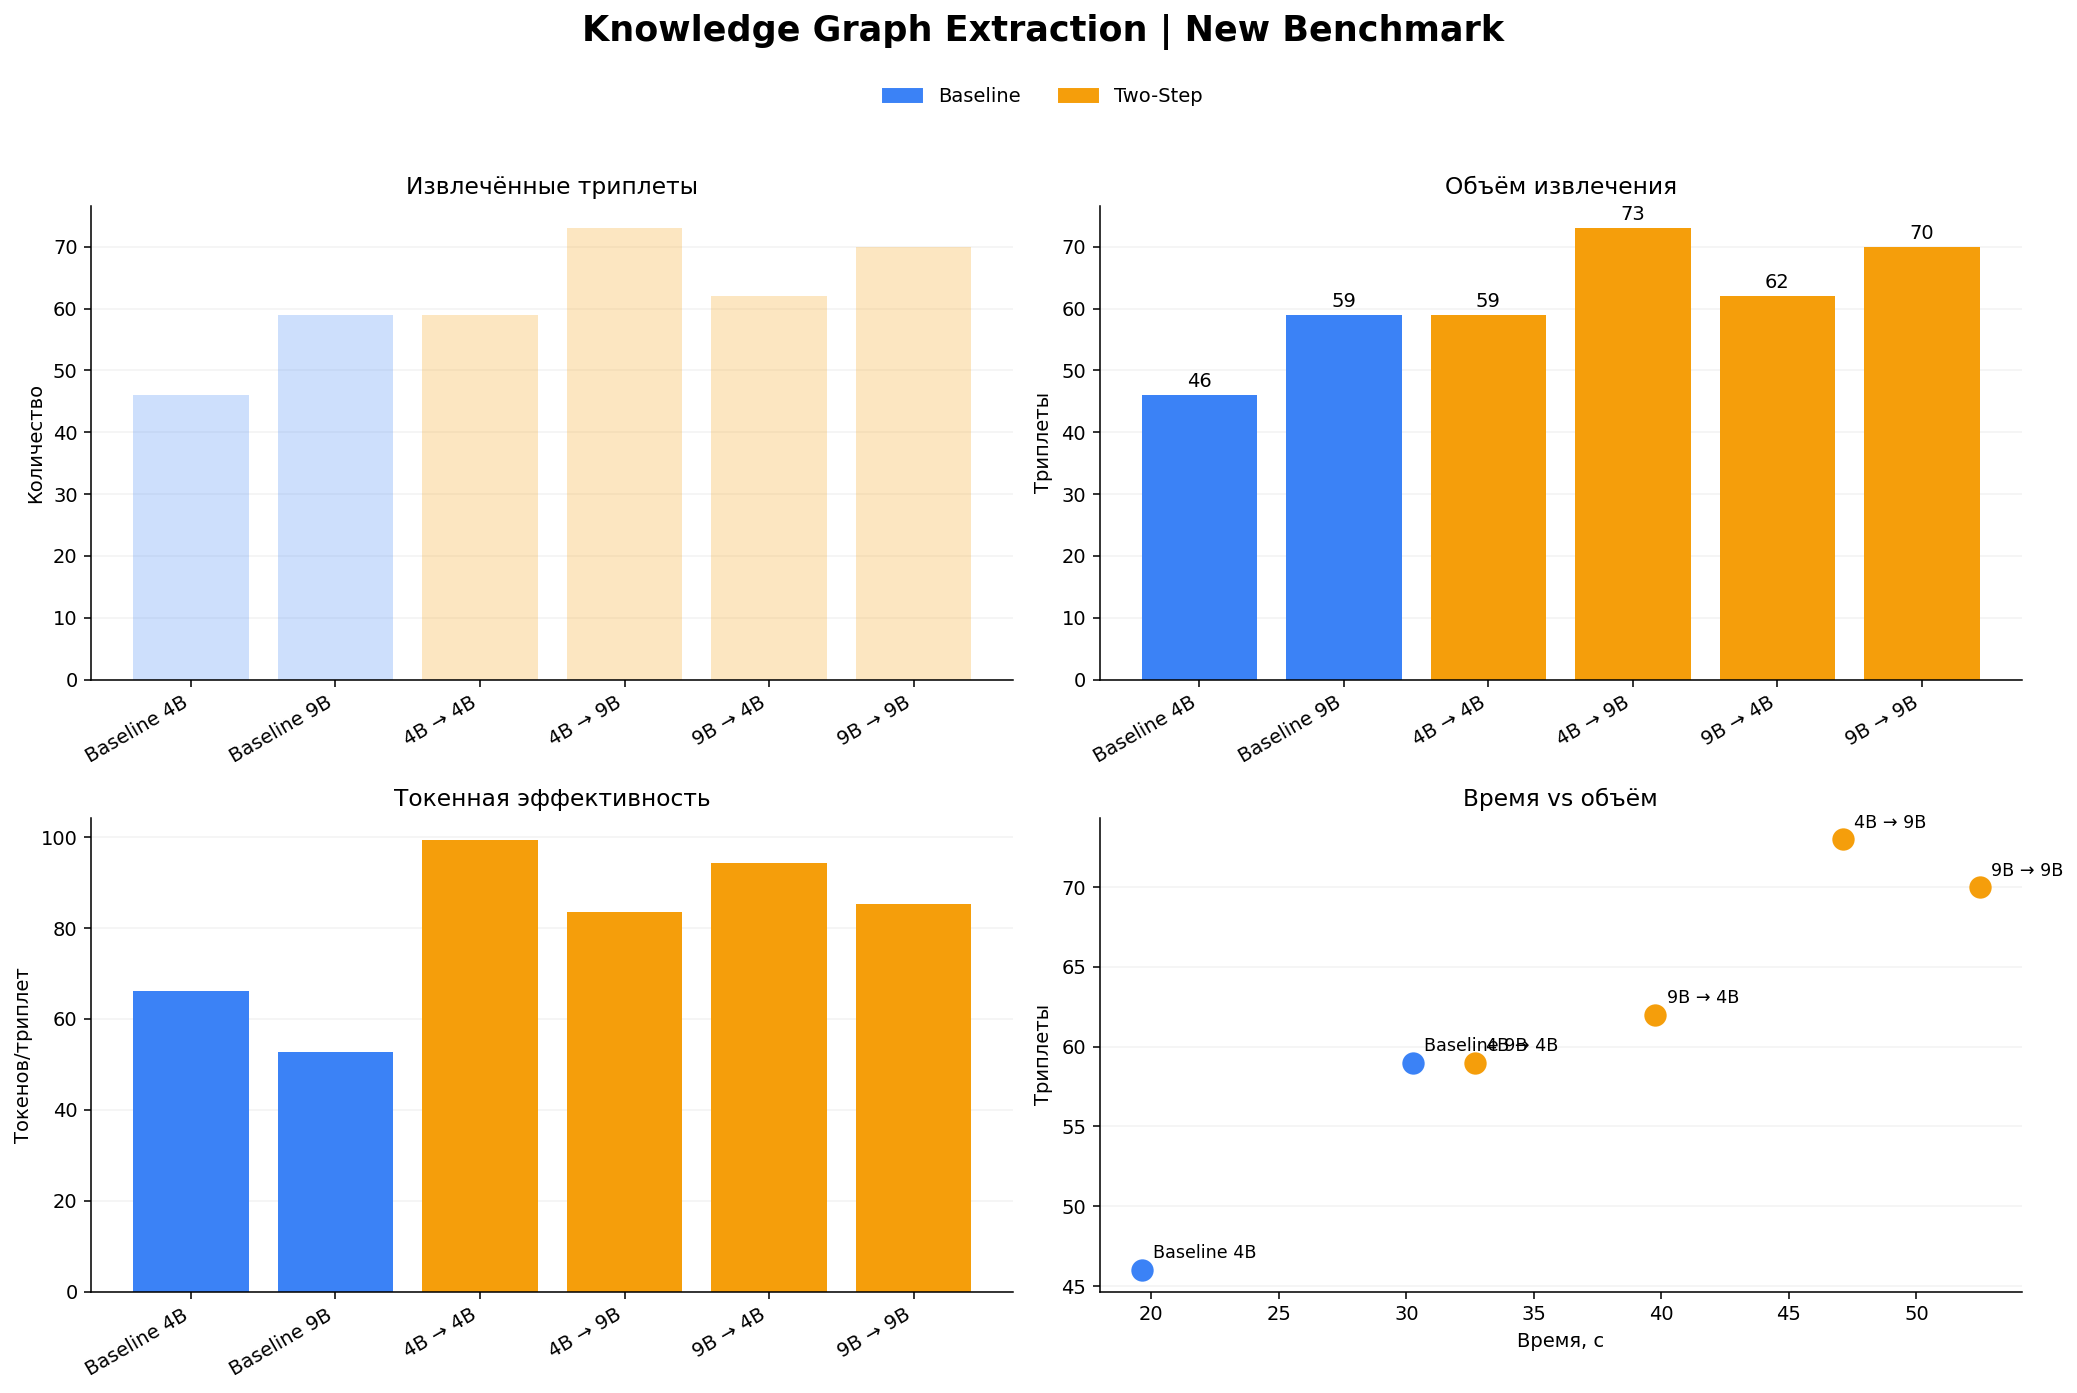

In [134]:
# Запускаем все шесть конфигураций
text = open("alexander_the_great.txt", encoding="utf-8").read()

df, results = benchmark(text)

# Изучаем результаты
for name, result in results.items():
    print(f"\n=== {name} ===")
    for triple in result["triples"]:
        print(triple)

In [135]:
display(df.round(1))

,Триплеты,Токены,"Время, с",Токенов/триплет,Секунд/триплет
Конфигурация,,,,,
Baseline 4B,46,3038,19.6,66.0,0.4
Baseline 9B,59,3105,30.2,52.6,0.5
4B → 4B,59,5859,32.7,99.3,0.6
4B → 9B,73,6104,47.1,83.6,0.6
9B → 4B,62,5850,39.7,94.4,0.6
9B → 9B,70,5966,52.5,85.2,0.7


,Триплеты,Токены,"Время, с",Токенов/триплет,Секунд/триплет,"Из них, верных",Ошибок,"Precision, %","Recall*, %","F1*, %",Токенов/верный,Секунд/верный
Конфигурация,,,,,,,,,,,,
Baseline 4B,46,3038,19.6,66.0,0.4,21,25,45.7,70.0,55.3,144.7,0.9
Baseline 9B,59,3105,30.2,52.6,0.5,46,13,78.0,153.3,103.4,67.5,0.7
4B → 4B,59,5859,32.7,99.3,0.6,42,17,71.2,140.0,94.4,139.5,0.8
4B → 9B,73,6104,47.1,83.6,0.6,62,11,84.9,206.7,120.4,98.5,0.8
9B → 4B,62,5850,39.7,94.4,0.6,46,16,74.2,153.3,100.0,127.2,0.9
9B → 9B,70,5966,52.5,85.2,0.7,59,11,84.3,196.7,118.0,101.1,0.9


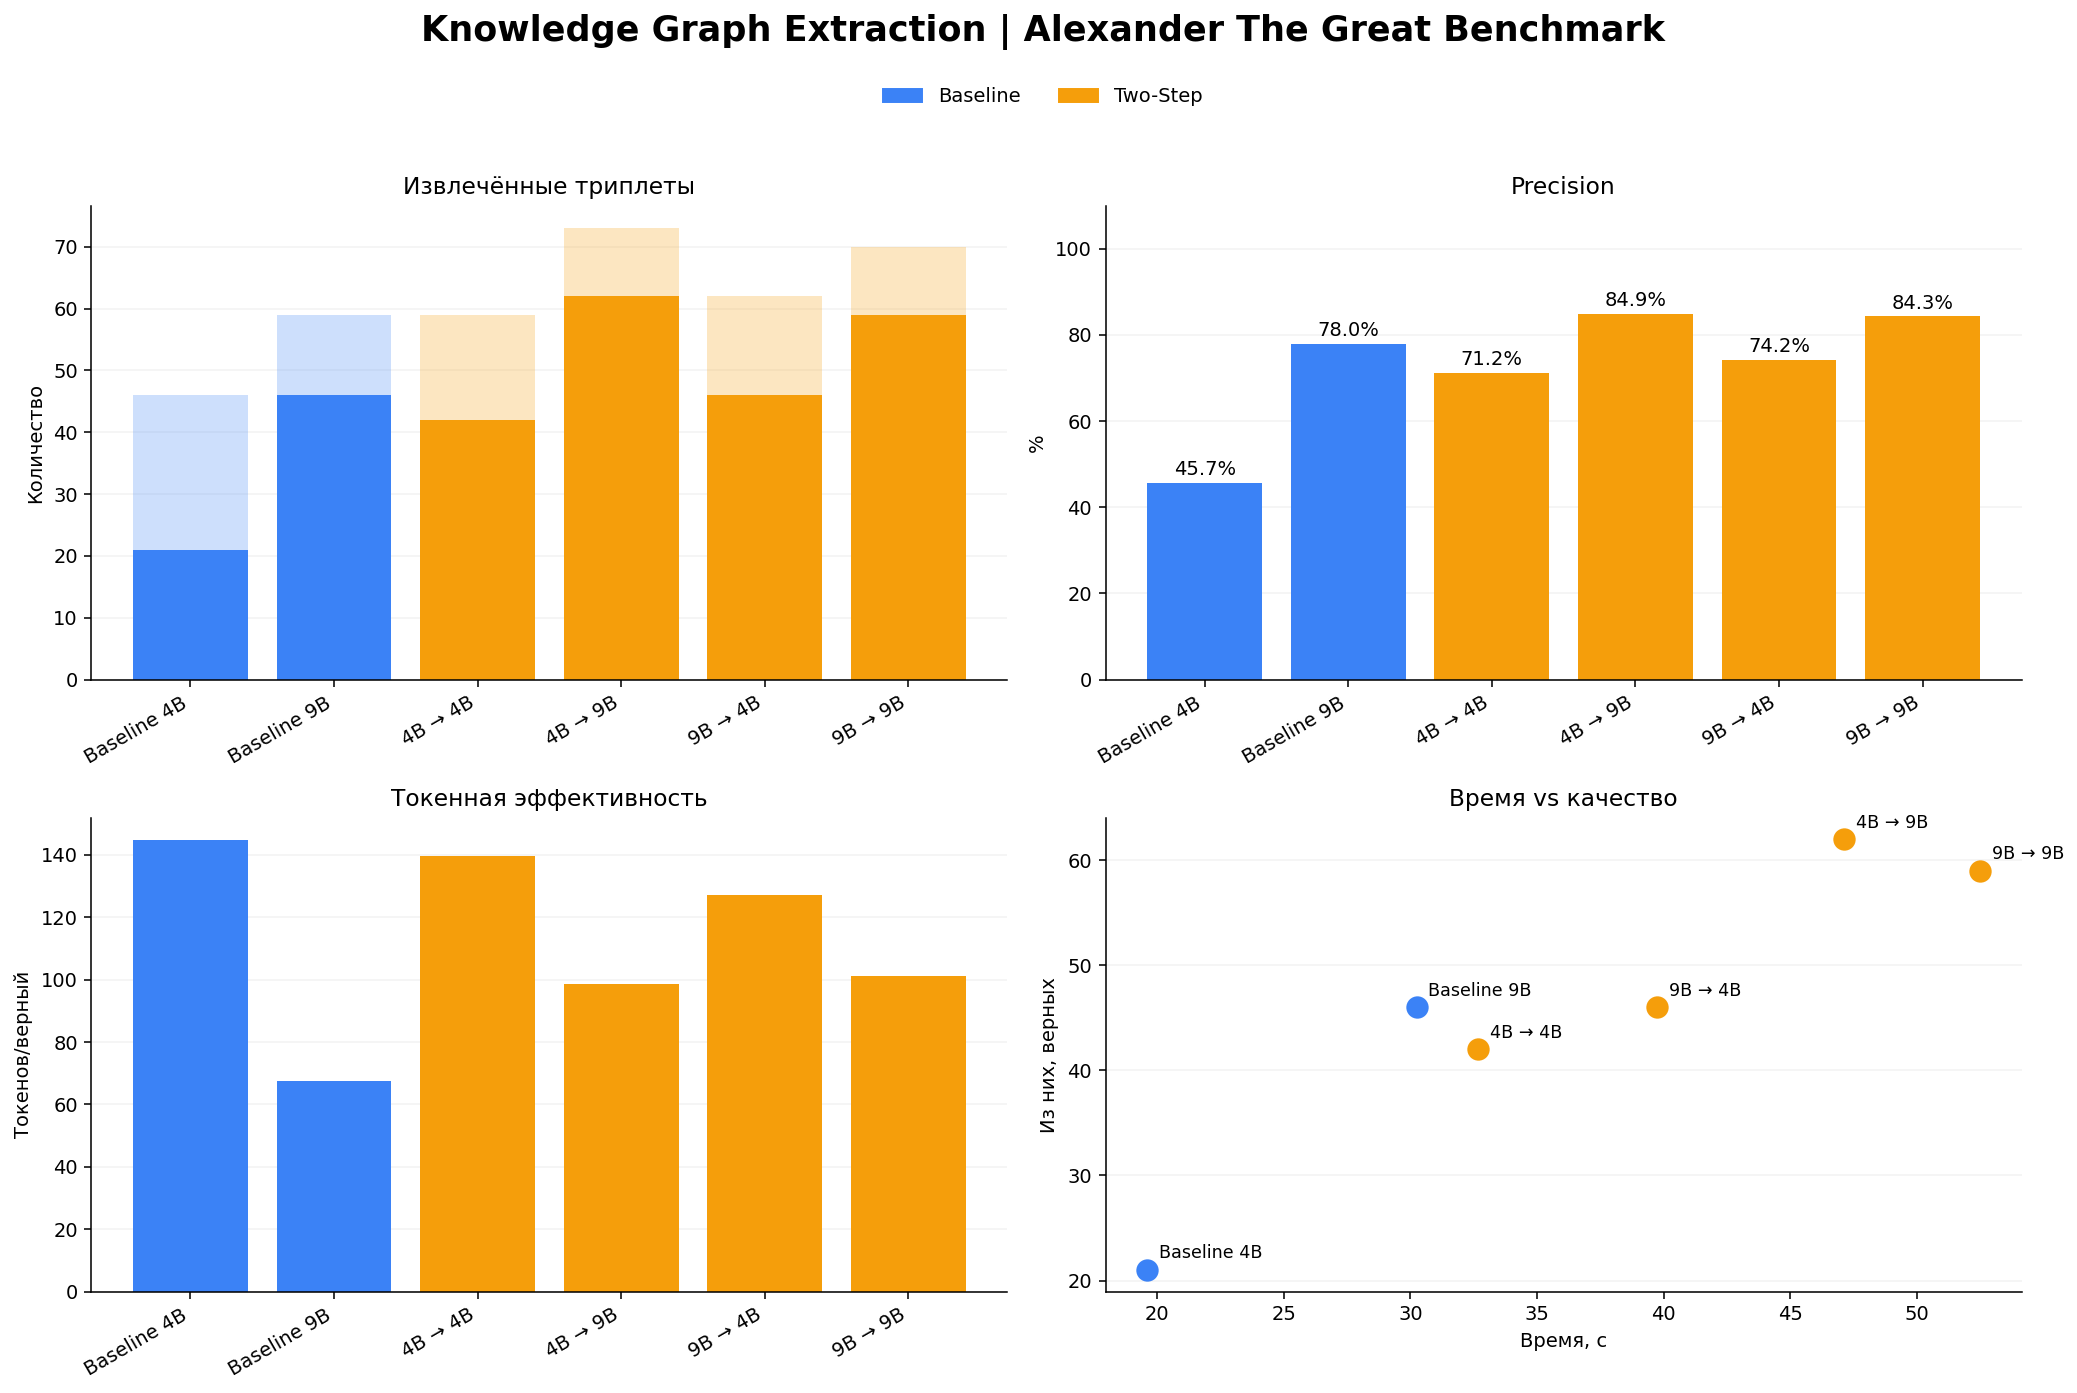

In [137]:
correct = {
    "Baseline 4B": 21,
    "Baseline 9B": 46,
    "4B → 4B": 42,
    "4B → 9B": 62,
    "9B → 4B": 46,
    "9B → 9B": 59,
}

# Замени нули результатами оценки
df = evaluate(df, correct, gold_size=30)

display(df.round(1))

fig = plot_benchmark(df, "Knowledge Graph Extraction | Alexander The Great Benchmark")
fig.savefig("benchmark.png", dpi=250, bbox_inches="tight")
plt.show()